# FLUX.2-klein-4B 로 이미지 생성하기 (Colab + ComfyUI)

Black Forest Labs 의 최신 텍스트→이미지 모델 **FLUX.2-klein-4B** 를
Google Colab(무료 GPU)에서 **ComfyUI** 로 실행하고, **Gradio** 로 UI 까지 띄우는 실습입니다.

---

## 학습 목표
- 텍스트→이미지 생성 모델의 **전체 파이프라인** 이해
- **양자화(GGUF Q4)** 가 왜 필요한지 체감 (16GB → 2.6GB)
- **ComfyUI** 의 노드 기반 동작 원리와 **API 호출** 이해
- **Gradio** 로 나만의 이미지 생성 UI 만들기

---

## 왜 이 구성인가? (핵심 개념)

| 시도 | 결과 | 이유 |
|---|---|---|
| 풀 BF16 모델 | Colab RAM 부족 | 모델 크기 ~16GB > Colab 시스템 RAM(~13GB) |
| fp8 단일 파일 | diffusers 미지원 | `from_single_file` 메서드가 없음 |
| **GGUF Q4 + ComfyUI** | **성공** | 2.6GB 로 축소, ComfyUI 가 GGUF 네이티브 지원 |

> **양자화(Quantization)**: 모델 가중치의 숫자 정밀도를 낮춰(예: 16비트→4비트)
> 크기와 메모리를 줄이는 기술. 품질 손실은 거의 없습니다.

---

## 모델 구성 (3가지 파일이 하나의 파이프라인을 이룸)

| 역할 | 파일 | 설명 |
|---|---|---|
| **디퓨전 모델** | `flux-2-klein-4b-Q4_K_M.gguf` | 텍스트를 이해해 이미지를 그려내는 핵심 (4B, 양자화 2.6GB) |
| **텍스트 인코더** | `qwen_3_4b.safetensors` | 프롬프트를 모델이 이해하는 숫자로 변환 (Qwen3-4B) |
| **VAE** | `flux2-vae.safetensors` | 압축된 latent 를 최종 픽셀 이미지로 복원 |

> 이 세 가지가 합쳐져야 비로소 "텍스트 → 이미지" 가 완성됩니다.

---

## 실습 준비
1. 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 선택 후 저장
2. 아래 셀을 **1번부터 순서대로** 실행 (모델 다운로드에 시간이 좀 걸립니다 ~11GB)

## [단계 1] 런타임에 GPU 가 있는지 확인

이 실습은 GPU(그래픽카드) 없이는 실행할 수 없습니다. 현재 Colab 런타임이 GPU 를 인식하고 있는지, 인식한다면 어떤 종류(T4 등)이고 VRAM(비디오 메모리)은 얼마인지 확인합니다.

GPU가 감지되지 않으면 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 로 바꾼 뒤 이 셀을 다시 실행해야 합니다.

In [1]:
# 1) GPU 가 사용 가능한지 확인
import torch

print("PyTorch 버전:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("GPU가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")

PyTorch 버전: 2.14.1+cu130
CUDA 사용 가능: True
GPU: Tesla T4
VRAM(GB): 15.64


## [단계 2] ComfyUI 본체와 GGUF 노드 설치

**ComfyUI** 는 노드(node) 기반의 이미지 생성 도구로, 각 기능(모델 로드, 텍스트 인코딩, 샘플링 등)을 블록처럼 연결해 파이프라인을 구성합니다. 이 실습에서는 ComfyUI 를 **웹 UI 없이 API 서버로만** 사용합니다.

여기에 더해 **ComfyUI-GGUF** 라는 커스텀 노드(플러그인)를 설치합니다. ComfyUI 기본 기능은 GGUF 포맷을 읽지 못하기 때문에, 양자화 모델을 로드하려면 이 플러그인이 필요합니다.

In [2]:
# 2) ComfyUI 본체 + GGUF 노드(플러그인) 설치
import os

%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone https://github.com/comfyanonymous/ComfyUI.git   # ComfyUI 본체

%cd /content/ComfyUI
!pip install -q -r requirements.txt                            # ComfyUI 의존성

# GGUF 파일을 읽기 위한 커스텀 노드 설치
%cd /content/ComfyUI/custom_nodes
if not os.path.isdir("ComfyUI-GGUF"):
    !git clone https://github.com/city96/ComfyUI-GGUF.git      # GGUF 로더 노드
%cd /content/ComfyUI
!pip install -q gguf                                           # GGUF 파싱 라이브러리

print("\n완료: ComfyUI + GGUF 노드 설치")

/content
Cloning into 'ComfyUI'...
remote: Enumerating objects: 65068, done.
remote: Counting objects: 100% (882/882), done.
remote: Compressing objects: 100% (269/269), done.
remote: Total 65068 (delta 748), reused 613 (delta 613), pack-reused 64186 (from 2)
Receiving objects: 100% (65068/65068), 99.79 MiB | 18.51 MiB/s, done.
Resolving deltas: 100% (45069/45069), done.
/content/ComfyUI
/content/ComfyUI/custom_nodes
Cloning into 'ComfyUI-GGUF'...
remote: Enumerating objects: 814, done.
remote: Counting objects: 100% (570/570), done.
remote: Compressing objects: 100% (206/206), done.
remote: Total 814 (delta 515), reused 364 (delta 364), pack-reused 244 (from 1)
Receiving objects: 100% (814/814), 187.82 KiB | 12.52 MiB/s, done.
Resolving deltas: 100% (545/545), done.
/content/ComfyUI

완료: ComfyUI + GGUF 노드 설치


## [단계 3] 모델 파일 3종 다운로드

위 개요에서 설명한 대로, FLUX.2-klein 파이프라인은 **세 가지 파일**로 구성됩니다. 각 파일을 ComfyUI 가 정해둔 표준 폴더에 다운로드합니다.

- **디퓨전 모델** (2.6GB) - GGUF Q4 양자화본. 이미지 생성의 핵심 두뇌
- **텍스트 인코더** (8GB) - Qwen3-4B. 프롬프트를 숫자로 변환
- **VAE** (330MB) - latent 를 사람이 보는 픽셀 이미지로 복원

이미 받은 파일은 건너뛰도록 되어 있어, 런타임이 끊기고 다시 실행해도 처음부터 받지 않습니다. 총 약 11GB 로 시간이 꽤 걸립니다.

In [8]:
# 3) 파이프라인 구성 파일 3종 다운로드 → ComfyUI 표준 폴더에 배치
import os
%cd /content/ComfyUI

# ComfyUI 가 모델을 찾는 표준 경로 생성
os.makedirs("models/diffusion_models", exist_ok=True)   # 디퓨전 모델
os.makedirs("models/text_encoders",  exist_ok=True)   # 텍스트 인코더
os.makedirs("models/vae",            exist_ok=True)   # VAE

def 다운로드(url, 저장경로):
    """이미 받았으면 건너뛰고, 아니면 wget 로 받는 헬퍼"""
    if os.path.exists(저장경로) and os.path.getsize(저장경로) > 1_000_000:
        print(f"  ↳ 이미 있음: {저장경로} ({os.path.getsize(저장경로)/1e9:.2f} GB)")
        return
    print(f"  ↳ 다운로드 중...")
    !wget -q --show-progress -O "{저장경로}" "{url}"

print("[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)")
다운로드("https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
        "models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf")

print("[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
        "models/text_encoders/qwen_3_4b.safetensors")

print("[3/3] VAE (약 330MB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
        "models/vae/flux2-vae.safetensors")

print("\n다운로드 완료. 배치된 파일 확인:")
!ls -lh models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf \
      models/text_encoders/qwen_3_4b.safetensors \
      models/vae/flux2-vae.safetensors

/content/ComfyUI
[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)
  ↳ 다운로드 중...
models/diffusion_mo 100%[===================>]   2.42G  72.1MB/s    in 37s     
[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)
  ↳ 다운로드 중...
models/text_encoder 100%[===================>]   7.49G  51.1MB/s    in 1m 56s  
[3/3] VAE (약 330MB)
  ↳ 다운로드 중...
models/vae/flux2-va 100%[===================>] 320.64M  30.8MB/s    in 5.5s    

다운로드 완료. 배치된 파일 확인:
-rw-r--r-- 1 root root 2.5G Nov 11 07:54 models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf
-rw-r--r-- 1 root root 7.5G Nov 11 07:56 models/text_encoders/qwen_3_4b.safetensors
-rw-r--r-- 1 root root 321M Nov 11 07:56 models/vae/flux2-vae.safetensors


## [단계 4] ComfyUI 서버 실행

ComfyUI 를 **백그라운드 프로세스**로 띄웁니다. 이 서버는 Colab 컨테이너 내부의 `http://127.0.0.1:8188` 에서 HTTP API 로 동작하며, 다음 단계의 Gradio UI 가 이 서버에 요청을 보내는 구조입니다.

실행 후 `http 200` 응답이 확인되면 서버가 준비된 것입니다. 이 셀이 실행 중인 동안 서버가 계속 유지됩니다.

In [9]:
# 4) ComfyUI 서버를 백그라운드로 실행 (Gradio 가 이 서버에 접속함)
#    ※ Gradio 를 쓰므로 외부 공개 터널은 필요 없습니다.
import subprocess, os, time

%cd /content/ComfyUI

# 혹시 떠 있는 예전 서버가 있으면 정리
!pkill -f "main.py" 2>/dev/null
time.sleep(2)

# ComfyUI 백그라운드 실행 (포트 8188)
os.system("nohup python main.py --listen 0.0.0.0 --port 8188 > /content/comfyui.log 2>&1 &")

# 서버가 뜰 때까지 대기 (로컬에서 200 응답이 오면 준비 완료)
print("ComfyUI 기동 대기 중...")
for _ in range(40):
    time.sleep(1)
    code = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/",
                          shell=True, capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)")
        break
else:
    print("서버가 안 뜹니다. 로그:")
    print(open("/content/comfyui.log").read()[-800:])

/content/ComfyUI
^C
ComfyUI 기동 대기 중...
완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)


Saving pose_01.webp to pose_01.webp


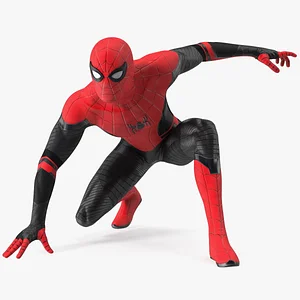

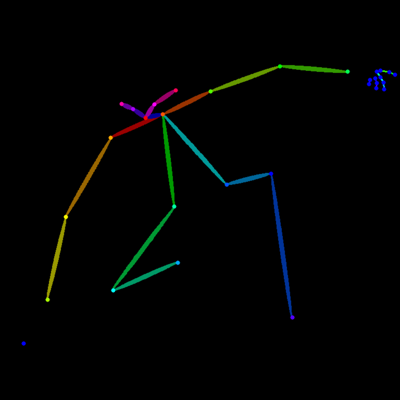

In [19]:
# [단계 5] 참조 사진에서 OpenPose 로 관절(포즈) 뽑기
# 이 셀이 하는 일: 사람 사진 1장을 올리면, 관절 위치만 선으로 그린 "뼈대 이미지"를 만들어 저장합니다.
#                 이 뼈대 이미지가 ControlNet 방식에서 말하는 "전처리 결과(조건 이미지)"입니다.

!pip install -q controlnet_aux            # OpenPose 등 ControlNet 용 전처리기 모음 라이브러리

import os
from google.colab import files
from PIL import Image as PILImage
from controlnet_aux import OpenposeDetector

NO = "01"                                 # 두 번째 포즈를 실험할 때는 "02" 로 바꿔 다시 실행
os.makedirs("/content/samples", exist_ok=True)

# ① 참조 사진 업로드 (전신 또는 상반신이 또렷하게 나온 사람 사진 1장)
uploaded = files.upload()
ref_img = PILImage.open(list(uploaded.keys())[0]).convert("RGB")

# ② OpenPose 모델 불러오기 (첫 실행 때만 가중치를 내려받음)
openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")

# ③ 관절 추출 → 검은 배경 위에 뼈대만 그린 이미지가 나옴
pose_img = openpose(
    ref_img,
    include_body=True,       # 몸통·팔·다리 관절
    include_hand=True,       # 손가락 관절
    include_face=False,      # 얼굴은 제외 (참조 인물의 얼굴 생김새가 따라오지 않게)
    detect_resolution=768,   # 관절을 찾을 때 쓰는 해상도 (높을수록 정밀하지만 느림)
    image_resolution=1024,   # 결과 뼈대 이미지의 해상도
)

# ④ 원본 참조 사진과 뼈대 이미지를 samples/ 에 저장하고 화면에서 확인
ref_img.save(f"/content/samples/pose_{NO}.png")
pose_img.save(f"/content/samples/pose_{NO}_skeleton.png")
for im in (ref_img, pose_img):
    preview = im.copy(); preview.thumbnail((400, 400)); display(preview)

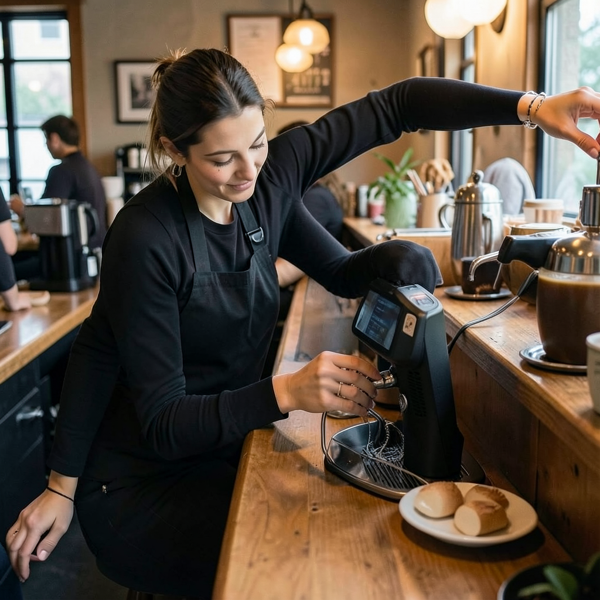

In [20]:
# [단계 6] 뼈대 이미지 + 프롬프트 → 같은 자세의 새 이미지 생성
# 이 셀이 하는 일: 5단계의 뼈대 이미지를 "자세 조건"으로, 프롬프트를 "내용 조건"으로
#                 함께 ComfyUI 서버에 보내 이미지를 만들고 samples/ 에 저장합니다.
import io, json, time, urllib.parse
import requests
from PIL import Image as PILImage

SERVER = "http://127.0.0.1:8188"          # 4단계에서 띄운 ComfyUI 서버 주소

# 모델에게 "참조 이미지는 자세만 참고하라"고 알려 주는 고정 지시문 (내 프롬프트 앞에 붙음)
POSE_GUIDE = ("The reference image is an OpenPose stick-figure skeleton. Use it only as a pose guide. "
              "Create a new image of a person whose body, arms and legs match the skeleton's pose exactly. "
              "Do not draw the skeleton lines or dots. ")

def generate_with_pose(pose_path, prompt, out_path, steps=4, seed=42):
    # ① 뼈대 이미지를 약 100만 픽셀, 16의 배수 크기로 맞춤
    #    결과 이미지도 같은 크기로 만들어야 뼈대 위치와 결과 속 인물 위치가 어긋나지 않음
    pose = PILImage.open(pose_path).convert("RGB")
    scale = (1024 * 1024 / (pose.width * pose.height)) ** 0.5
    width  = round(pose.width  * scale / 16) * 16
    height = round(pose.height * scale / 16) * 16
    buf = io.BytesIO(); pose.resize((width, height)).save(buf, format="PNG"); buf.seek(0)

    # ② 뼈대 이미지를 ComfyUI 서버에 업로드 (LoadImage 노드가 읽을 수 있게)
    up = requests.post(f"{SERVER}/upload/image",
                       files={"image": (f"pose_{int(time.time())}.png", buf, "image/png")},
                       data={"overwrite": "true"}, timeout=30)
    up.raise_for_status()
    pose_name = up.json()["name"]

    # ③ 워크플로우(노드 그래프) 조립: 기존 텍스트→이미지 구성에 "포즈 조건" 노드 20~23 을 추가
    wf = {
      # --- 모델 3종 로드 (기존과 동일) ---
      "10": {"class_type": "UnetLoaderGGUF", "inputs": {"unet_name": "flux-2-klein-4b-Q4_K_M.gguf"}},
      "8":  {"class_type": "CLIPLoader",     "inputs": {"clip_name": "qwen_3_4b.safetensors", "type": "flux2"}},
      "4":  {"class_type": "VAELoader",      "inputs": {"vae_name": "flux2-vae.safetensors"}},
      # --- 프롬프트 조건 ---
      "6":  {"class_type": "CLIPTextEncode",      "inputs": {"text": POSE_GUIDE + prompt, "clip": ["8", 0]}},  # 프롬프트 → 숫자
      "7":  {"class_type": "ConditioningZeroOut", "inputs": {"conditioning": ["6", 0]}},                       # 빈 네거티브 조건
      # --- 포즈 조건 (새로 추가한 부분) ---
      "20": {"class_type": "LoadImage",       "inputs": {"image": pose_name}},                         # 뼈대 이미지 불러오기
      "21": {"class_type": "VAEEncode",       "inputs": {"pixels": ["20", 0], "vae": ["4", 0]}},       # 뼈대 이미지 → latent
      "22": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["6", 0], "latent": ["21", 0]}},  # 프롬프트 조건에 포즈를 붙임
      "23": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["7", 0], "latent": ["21", 0]}},  # 네거티브 쪽에도 동일하게
      # --- 샘플링 (FLUX.2 전용 노드 구성) ---
      "5":  {"class_type": "EmptyFlux2LatentImage", "inputs": {"width": width, "height": height, "batch_size": 1}},  # 빈 캔버스
      "12": {"class_type": "Flux2Scheduler",  "inputs": {"steps": int(steps), "width": width, "height": height}},   # 노이즈 제거 일정
      "13": {"class_type": "KSamplerSelect",  "inputs": {"sampler_name": "euler"}},                                 # 샘플러 종류
      "14": {"class_type": "RandomNoise",     "inputs": {"noise_seed": int(seed)}},                                 # 시작 노이즈(시드)
      "15": {"class_type": "CFGGuider",       "inputs": {"model": ["10", 0], "positive": ["22", 0],
                                                         "negative": ["23", 0], "cfg": 1.0}},          # 조건을 모델에 연결
      "3":  {"class_type": "SamplerCustomAdvanced", "inputs": {"noise": ["14", 0], "guider": ["15", 0], "sampler": ["13", 0],
                                                               "sigmas": ["12", 0], "latent_image": ["5", 0]}},  # 실제 생성
      # --- 결과 복원·저장 ---
      "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["3", 0], "vae": ["4", 0]}},             # latent → 픽셀 이미지
      "11": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "pose_tool"}},
    }

    # ④ 생성 요청을 보내고, 끝날 때까지 2초마다 확인 (폴링)
    r = requests.post(f"{SERVER}/prompt", json={"prompt": wf, "client_id": "colab"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:500]}")
    pid = r.json()["prompt_id"]
    for _ in range(180):
        time.sleep(2)
        h = requests.get(f"{SERVER}/history/{pid}", timeout=10).json()
        if pid not in h:
            continue
        if h[pid].get("status", {}).get("status_str") == "error":
            raise RuntimeError("ComfyUI 실행 에러: " + json.dumps(h[pid]["status"].get("messages", []), ensure_ascii=False)[:800])
        img = h[pid]["outputs"]["11"]["images"][0]
        break
    else:
        raise TimeoutError("6분 안에 끝나지 않았습니다.")

    # ⑤ 완성된 이미지를 내려받아 samples/ 에 저장
    q = urllib.parse.urlencode({"filename": img["filename"], "subfolder": img.get("subfolder", ""), "type": img.get("type", "output")})
    with open(out_path, "wb") as f:
        f.write(requests.get(f"{SERVER}/view?{q}", timeout=30).content)
    return PILImage.open(out_path)

# ---------- 실행: 프롬프트만 바꿔 가며 쓰면 됩니다 ----------
PROMPT = "a female barista"
result = generate_with_pose(f"/content/samples/pose_{NO}_skeleton.png", PROMPT, f"/content/samples/output_{NO}.png")
preview = result.copy(); preview.thumbnail((600, 600)); display(preview)